# 03 · Clustering no supervisado de películas

El clustering usa **solo metadatos** (genoma de tags y géneros/título para interpretar), **no ratings de val/test**.
La evaluación del modelo supervisado se cruza únicamente como análisis descriptivo posterior, usando el `cluster_assignments.csv` ya generado.

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent
R = ROOT / "reports/results"
FIG = ROOT / "reports/figures"

ksel = pd.read_csv(R / "cluster_k_selection.csv")
prof = pd.read_csv(R / "cluster_profiles.csv")
assign = pd.read_csv(R / "cluster_assignments.csv")
err = pd.read_csv(R / "errors_by_cluster.csv")
summary = (R / "cluster_summary.txt").read_text(encoding="utf-8")
print(summary)
print("películas asignadas:", len(assign))

k=7
pca_var=0.662
ari_mean=0.838
ari_all=[0.48612539582557196, 0.9089279889279017, 0.9975043426566237, 0.958546617338768]

películas asignadas: 10158


## Representación: genoma de tags → PCA

Cada película se representa por **1 128 tags** del genoma (relevancia 0–1). Es una matriz densa de 10 158 × 1 128 en el subconjunto.
Se aplica **PCA de 30 componentes** antes de KMeans para: (i) reducir dimensionalidad y ruido, (ii) eliminar correlación entre tags y (iii) hacer tratable la distancia euclídea.
Los 30 componentes explican **0.662** de la varianza (66.2%). No se usan ratings ni popularidad para construir el espacio.

**Cobertura:** el genoma cubre **13 816 de 62 423** películas del dataset completo (22.1%). En este subconjunto cubre **10 158 de 10 158** (100%) porque el filtro de actividad retuvo películas populares, que son justamente las que tienen genoma. Es un sesgo de selección, no una cobertura universal.

## Elección de k: codo + silueta + estabilidad

La silueta máxima está en **k=7** (0.1058). El codo de inercia no es nítido: la inercia baja de forma gradual.
La estabilidad entre 5 semillas da un **ARI medio de 0.838**, pero el ARI de la primera semilla contra las demás es **0.486**, **0.909**, **0.998** y **0.959**: hay una partición distinta (probablemente por la frontera entre clusters afines). Por eso k=7 se toma como una solución **exploratoria**, no como una taxonomía estable.

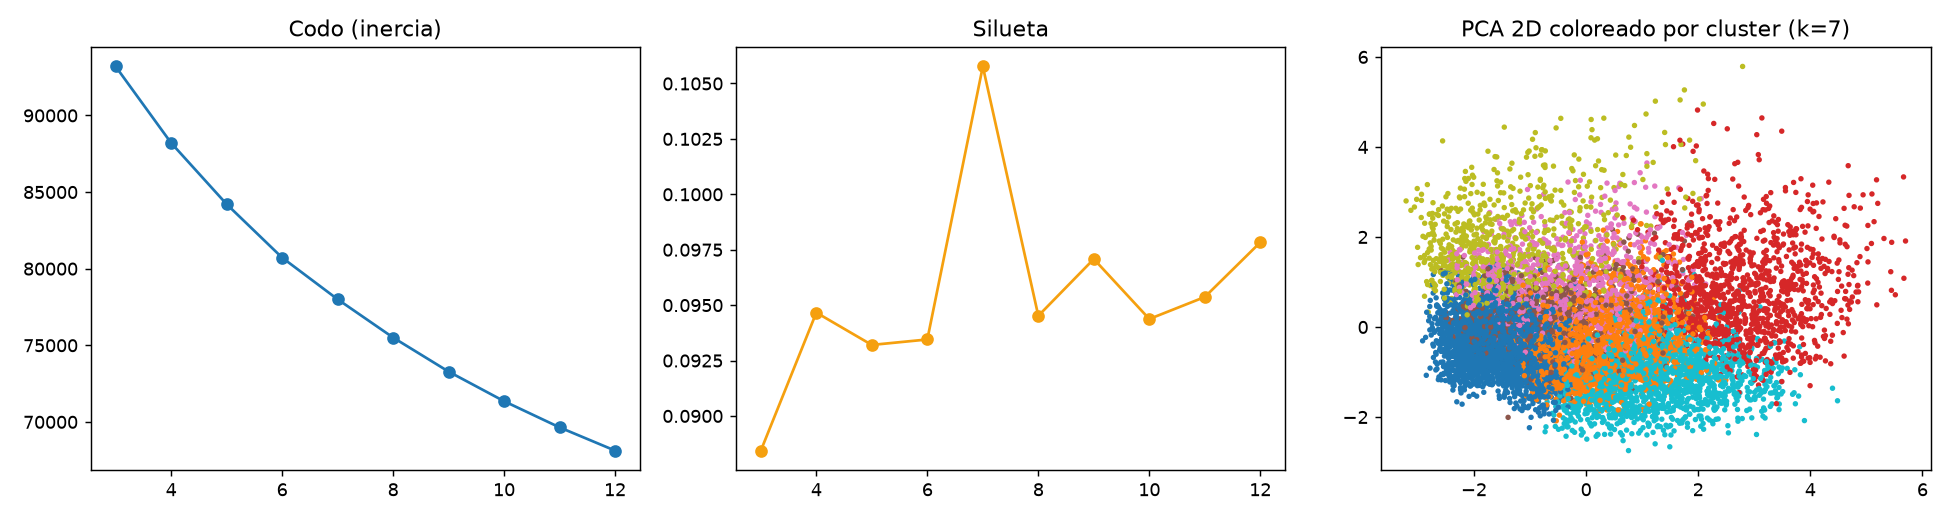

,k,inertia,silhouette
0,3,93197.7188,0.0884
1,4,88207.2109,0.0947
2,5,84210.1953,0.0932
3,6,80721.9219,0.0935
4,7,78003.0234,0.1058
5,8,75506.3281,0.0945
6,9,73284.1641,0.0971
7,10,71351.3359,0.0944
8,11,69642.9688,0.0954
9,12,68127.6016,0.0978


k elegido por silueta: 7 | silueta: 0.1058
inercia en k=3 y k=12: 93197.7 68127.6


In [2]:
display(Image(filename=FIG / "clustering_selection.png"))
display(ksel.round(4))
print("k elegido por silueta:", int(ksel.loc[ksel.silhouette.idxmax(), "k"]), "| silueta:", round(ksel.silhouette.max(), 4))
print("inercia en k=3 y k=12:", round(ksel.loc[ksel.k==3,"inertia"].iloc[0],1), round(ksel.loc[ksel.k==12,"inertia"].iloc[0],1))

**Lectura:** la silueta de 0.106 es baja; los clusters no están bien separados en el espacio PCA. Se interpretan como **segmentos descriptivos**, no como categorías reales.
El codo no permite una elección inequívoca; la silueta y la estabilidad se usan como apoyo, no como prueba de que existan 7 clases naturales.

## Perfiles e interpretación (nombres tentativos = hipótesis)

La tabla sale de `cluster_profiles.csv`: tags con mayor lift respecto a la media, géneros sobrerrepresentados, rating medio en train, año mediano y mediana de ratings por película.
Los nombres son **hipótesis de lectura**, no etiquetas verdaderas.

In [3]:
display(prof.round(3))
nombre = {
    0: "Comedia familiar / teen (hipótesis)",
    1: "Drama romántico sentimental (hipótesis)",
    2: "Cine aclamado / de premios (hipótesis)",
    3: "Terror gore / sobrenatural (hipótesis)",
    4: "Thriller criminal / acción (hipótesis)",
    5: "Blockbuster sci-fi / acción (hipótesis)",
    6: "Cine de autor / indie (hipótesis)",
}
tabla = prof.copy(); tabla.insert(1, "nombre_tentativo", tabla.cluster.map(nombre))
display(tabla[["cluster","nombre_tentativo","n_movies","top_genres","mean_rating","median_year","median_n_ratings"]].round(3))

,cluster,n_movies,top_tags,top_genres,mean_rating,median_year,median_n_ratings
0,0,2753,"comedy, predictable, funny, silly fun, teen mo...","Children, Comedy",2.899,1999.0,28.0
1,1,1942,"touching, sentimental, dramatic, heartwarming,...",Romance,3.581,1998.0,27.5
2,2,1262,"imdb top 250, great acting, tense, oscar (best...",NaN,3.853,1998.0,89.0
3,3,789,"horror, splatter, creepy, supernatural, blood,...","Horror, Thriller, Mystery, Sci-Fi",2.938,1997.0,22.0
4,4,1000,"thriller, action, murder, crime, suspense, cha...","Crime, Thriller, Mystery, Action",3.303,2000.0,36.0
5,5,797,"special effects, sci-fi, big budget, scifi, sc...","IMAX, Sci-Fi, Adventure, Action",3.085,2005.0,117.0
6,6,1615,"intimate, criterion, enigmatic, golden palm, l...","Drama, Romance",3.651,1998.0,17.0


,cluster,nombre_tentativo,n_movies,top_genres,mean_rating,median_year,median_n_ratings
0,0,Comedia familiar / teen (hipótesis),2753,"Children, Comedy",2.899,1999.0,28.0
1,1,Drama romántico sentimental (hipótesis),1942,Romance,3.581,1998.0,27.5
2,2,Cine aclamado / de premios (hipótesis),1262,NaN,3.853,1998.0,89.0
3,3,Terror gore / sobrenatural (hipótesis),789,"Horror, Thriller, Mystery, Sci-Fi",2.938,1997.0,22.0
4,4,Thriller criminal / acción (hipótesis),1000,"Crime, Thriller, Mystery, Action",3.303,2000.0,36.0
5,5,Blockbuster sci-fi / acción (hipótesis),797,"IMAX, Sci-Fi, Adventure, Action",3.085,2005.0,117.0
6,6,Cine de autor / indie (hipótesis),1615,"Drama, Romance",3.651,1998.0,17.0


- **Cluster 0 (2753 películas, “comedia familiar/teen”):** tags `comedy, predictable, funny, silly fun, teen movie`; géneros Children/Comedy; rating medio **2.899**, año mediano **1999**, popularidad mediana **28** ratings. Es el segmento peor valorado junto con terror.
- **Cluster 1 (1942, “drama romántico sentimental”):** `touching, sentimental, dramatic, heartwarming, love story`; Romance; rating **3.581**, año **1998**, popularidad **28**.
- **Cluster 2 (1262, “cine aclamado/de premios”):** `imdb top 250, great acting, oscar, masterpiece, social commentary`; rating **3.853**, el más alto de los siete; popularidad **89**, también la más alta.
- **Cluster 3 (789, “terror gore/sobrenatural”):** `horror, splatter, creepy, blood, gory, demons`; Horror/Thriller; rating **2.938**, año **1997**, popularidad **22**.
- **Cluster 4 (1000, “thriller criminal/acción”):** `thriller, action, murder, crime, suspense, corruption`; Crime/Thriller; rating **3.303**, año **2000**, popularidad **36**.
- **Cluster 5 (797, “blockbuster sci-fi/acción”):** `special effects, big budget, sci-fi, futuristic`; IMAX/Sci-Fi/Adventure; rating **3.085**, año **2005**, popularidad **117**.
- **Cluster 6 (1615, “cine de autor/indie”):** `intimate, criterion, enigmatic, golden palm, loneliness, melancholic, independent`; Drama/Romance; rating **3.651**, año **1998**, popularidad **17**. Comparte géneros con el cluster 1; los tags y la baja popularidad son los que los separan.

## Cruce descriptivo con el error del mejor modelo (bonus)

Se cruza `cluster_assignments.csv` con los errores del Item-KNN en test (modelo ya congelado; el cruce no se usa para elegir k ni el modelo).
El archivo `errors_by_cluster.csv` lo genera `error_analysis.py`.

,cluster,n,bias,mae,rmse
0,0,66929,0.1048,0.6930,0.9051
1,1,55017,0.0288,0.6284,0.8309
2,2,85019,0.0637,0.5838,0.7942
3,3,15266,0.1259,0.7188,0.9417
4,4,35221,0.0613,0.5977,0.7942
5,5,54868,0.0687,0.6307,0.8367
6,6,24568,0.0475,0.6792,0.9013


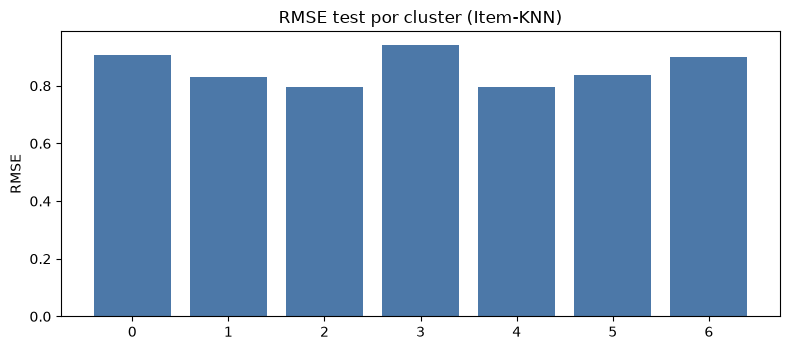

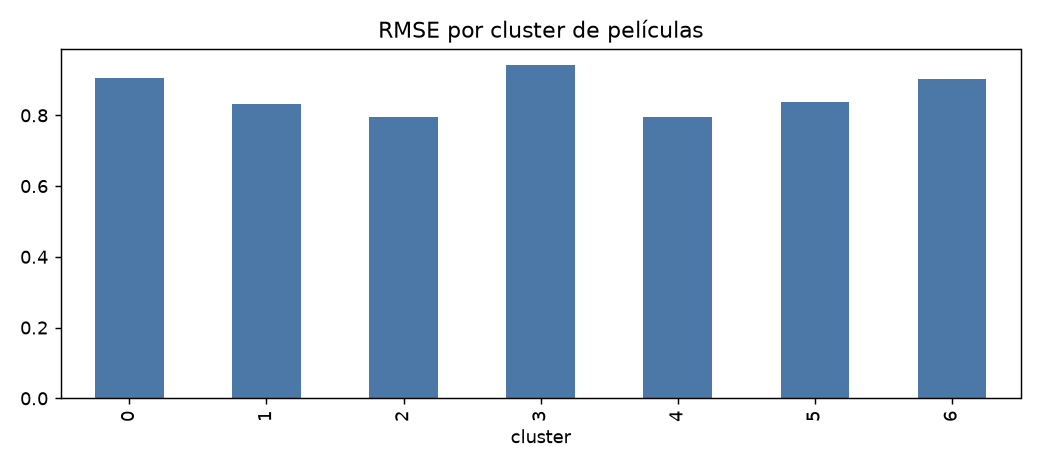

In [4]:
display(err.round(4))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(err.cluster.astype(str), err.rmse, color="#4c78a8"); ax.set_ylabel("RMSE"); ax.set_title("RMSE test por cluster (Item-KNN)")
plt.tight_layout(); plt.show()
display(Image(filename=FIG / "error_by_cluster.png"))

El mejor cluster es el **2** (“aclamado/de premios”): RMSE **0.7942** con **85019** ratings de test.
El peor es el **3** (“terror gore”): RMSE **0.9417** con **15266**.
Los clusters **0** (comedia) y **6** (indie) también superan 0.90; el **4** (thriller criminal) empata con el 2 en 0.7942.
La dispersión de RMSE entre clusters (**0.1475**) es mayor que la brecha entre Item-KNN y Funk SVD en test (0.0003), lo que sugiere que el tipo de película pesa más que la elección entre esos dos modelos.

## Limitaciones

1. **Cobertura del genoma:** 13 816 de 62 423 películas del dataset completo (22.1%). En el subconjunto es 100% por selección de películas populares; no se puede extrapolar a películas sin genoma.
2. **Silueta baja:** 0.106. Los clusters se solapan; no son categorías naturales ni una segmentación de negocio validada.
3. **Inestabilidad:** ARI medio 0.838, pero una semilla baja a 0.486. La frontera entre clusters afines (1/6, 2/4) es sensible a la inicialización.
4. **PCA lineal:** 30 componentes explican 66.2% de la varianza; se pierde el 33.8% y los componentes no tienen nombre.
5. **Interpretación circular:** los tags del genoma se usan para agrupar y también para nombrar; los nombres son hipótesis, no evidencia externa.
6. **Cruce con error:** es descriptivo y usa test; no se usó para elegir k, features ni modelo. El tamaño por cluster varía (15 266 a 85 019 ratings), así que las diferencias deben leerse con cautela.

## Conclusión

La representación por genoma + PCA permite una segmentación **exploratoria** en 7 grupos con perfiles distinguibles (comedia/teen, romance, cine aclamado, terror, thriller criminal, blockbuster sci-fi, indie). La evidencia no sostiene que sean 7 categorías reales: la silueta es baja y la estabilidad es moderada. El cruce con errores muestra que **terror (0.9417) y comedia (0.9051)** son los segmentos más difíciles y **cine aclamado (0.7942)** el más fácil; ese es el uso útil del clustering para la Parte II, no una taxonomía definitiva.